In [18]:
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt

In [19]:
df=pd.read_csv("/content/housing.csv")
df

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY
...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND


Data inspection


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [21]:
df.shape

(20640, 10)

In [22]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


In [23]:
df.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


In [24]:
df["total_bedrooms"] = df["total_bedrooms"].fillna(df["total_bedrooms"].median())

In [25]:
df.isnull().sum()

,0
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,0
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


Label encoding

In [26]:
from sklearn.preprocessing import LabelEncoder

In [27]:
encoder = LabelEncoder()
df["ocean_proximity"] = encoder.fit_transform(df["ocean_proximity"])
df.dtypes



,0
longitude,float64
latitude,float64
housing_median_age,float64
total_rooms,float64
total_bedrooms,float64
population,float64
households,float64
median_income,float64
median_house_value,float64
ocean_proximity,int64


Correlation heatmap

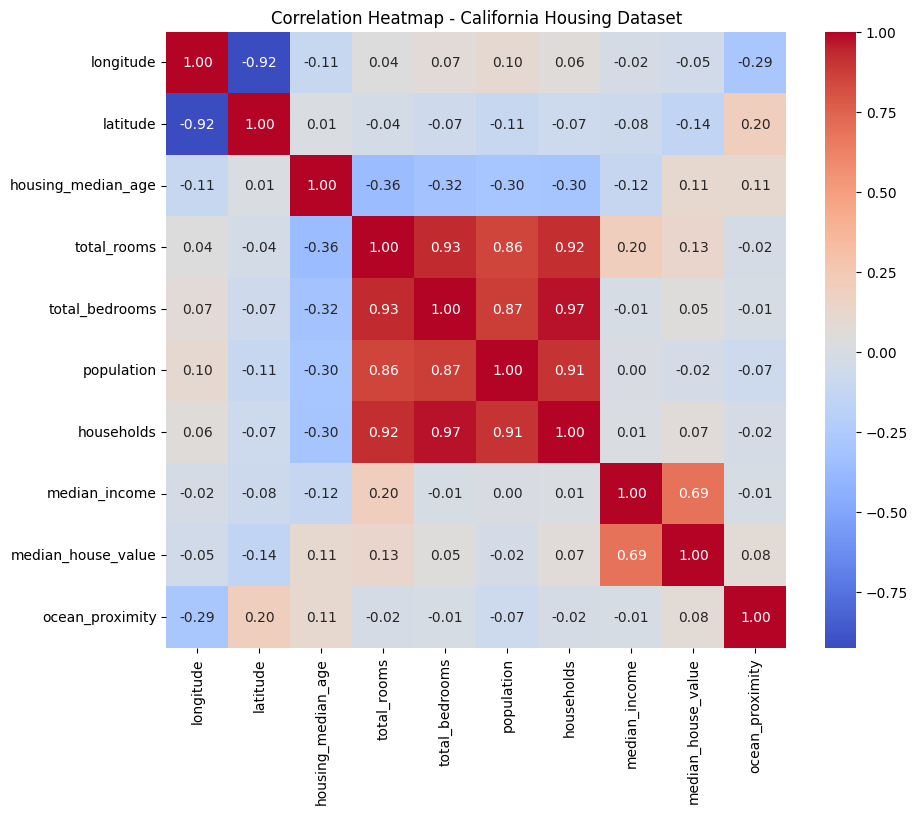

In [28]:
corr_matrix = df.corr()
# Plot heatmap
plt.figure(figsize=(10,8))
sn.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap - California Housing Dataset")
plt.show()

StandarScaler

In [29]:
from sklearn.preprocessing import StandardScaler


In [31]:
 #Selecte continuous col
continuous_cols=["housing_median_age","total_rooms","total_bedrooms","population","households","median_income"]
scaler = StandardScaler()
df[continuous_cols] = scaler.fit_transform(df[continuous_cols])
print(df.head())


   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88            0.982143    -0.804819       -0.972476   
1    -122.22     37.86           -0.607019     2.045890        1.357143   
2    -122.24     37.85            1.856182    -0.535746       -0.827024   
3    -122.25     37.85            1.856182    -0.624215       -0.719723   
4    -122.25     37.85            1.856182    -0.462404       -0.612423   

   population  households  median_income  median_house_value  ocean_proximity  
0   -0.974429   -0.977033       2.344766            452600.0                3  
1    0.861439    1.669961       2.332238            358500.0                3  
2   -0.820777   -0.843637       1.782699            352100.0                3  
3   -0.766028   -0.733781       0.932968            341300.0                3  
4   -0.759847   -0.629157      -0.012881            342200.0                3  


Splitting for trainning and tesing

In [33]:
from sklearn.model_selection import train_test_split

In [32]:
x=df.drop("median_house_value", axis=1)
y=df["median_house_value"]

In [34]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)


Ridge and Lassco

In [35]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error
# assign alpha values to test
alpha_values = [0.01, 0.1, 1, 10, 100]
# Ridge
ridge = Ridge()
ridge_params = {"alpha": alpha_values}
ridge_grid = GridSearchCV(ridge, ridge_params, cv=5, scoring="neg_mean_squared_error")
ridge_grid.fit(x_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_)
print("Best Ridge score:", -ridge_grid.best_score_)

# Lasso
lasso = Lasso(max_iter=10000)  # increase iterations for convergence
lasso_params = {"alpha": alpha_values}
lasso_grid = GridSearchCV(lasso, lasso_params, cv=5, scoring="neg_mean_squared_error")
lasso_grid.fit(x_train, y_train)

print("Best Lasso alpha:", lasso_grid.best_params_)
print("Best Lasso score:", -lasso_grid.best_score_)


Best Ridge alpha: {'alpha': 10}
Best Ridge score: 4836580755.466362
Best Lasso alpha: {'alpha': 10}
Best Lasso score: 4836978049.856996


LinearRegression

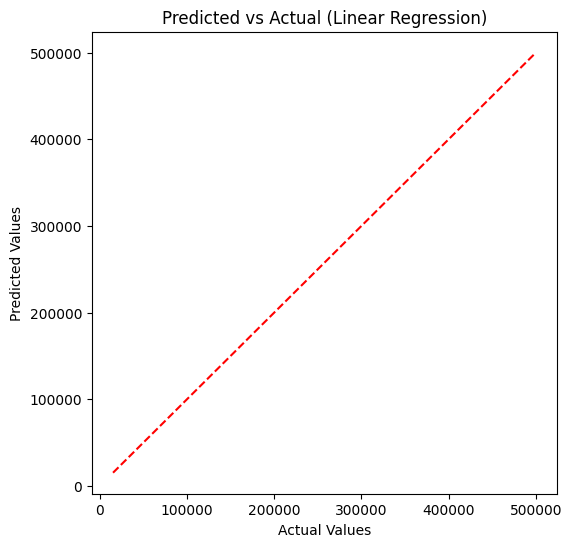

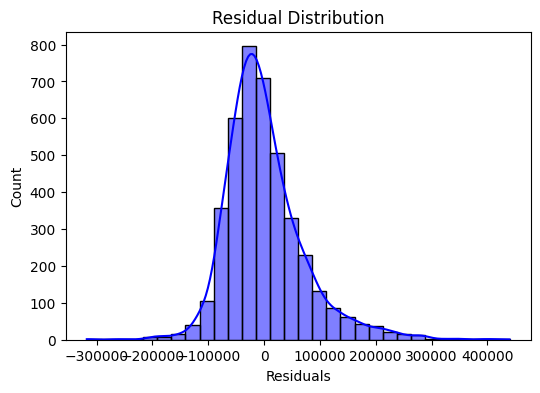

RMSE: 71147.87146118376
R² Score: 0.6137068886499535


In [38]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Fit Linear Regression
lin= LinearRegression()
lin.fit(x_train, y_train)

# Predictions
y_pred = lin.predict(x_test)

# Plot Predicted vs Actual
plt.figure(figsize=(6,6))
sn.scatterplot(X=y_test, Y=y_pred, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')
plt.xlabel("Actual Values")
plt.ylabel("Predicted Values")
plt.title("Predicted vs Actual (Linear Regression)")
plt.show()

# Plot Residuals
residuals = y_test - y_pred
plt.figure(figsize=(6,4))
sn.histplot(residuals, bins=30, kde=True, color="blue")
plt.xlabel("Residuals")
plt.title("Residual Distribution")
plt.show()

# Metrics
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R² Score:", r2_score(y_test, y_pred))
